# Step 2: Explore (Khám Phá & Phân Tích Dữ Liệu - EDA)
### Theo Quy Trình 8 Bước Từ Slide Bài Giảng Chapter 4 (NEU FIT)

---

### 1. Phân Tích Chuyên Sâu Cách Làm:
Slide 14 & 20 nêu rõ: *Output of this step: a written list of problems, before any of them is fixed.*
Chúng ta không vội làm sạch mà cần đóng vai trò "thanh tra dữ liệu":
- **Khảo sát cấu trúc & tóm tắt định lượng:** Dùng `info()` và `describe()` để nhận diện các giá trị bất khả thi (impossible values).
- **Rà soát giá trị khuyết (Missing values):** Xác định cột nào thiếu và tỷ lệ bao nhiêu.
- **Trực quan hóa đa chiều:**
  - 1 cột (Univariate): Histogram, Boxplot kiểm tra độ lệch (skew) và outlier.
  - 2 cột (Bivariate): Bar plot so sánh nhóm, Scatter plot tương quan, Line plot theo thời gian.
  - Nhiều cột (Multivariate): Correlation Heatmap phân tích mối quan hệ giữa biến số và biến mục tiêu.

### 2. Dùng Những Gì Để Làm?
- **Thư viện:** `pandas`, `matplotlib.pyplot`, `seaborn`.
- **Hàm & Phương pháp:** `df.info()`, `df.describe().round(1)`, `df.isna().sum()`, `plt.hist`, `plt.boxplot`, `sns.heatmap`.

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

for p in [os.path.abspath(".."), os.path.abspath("."), os.path.abspath("../..")]:
    if os.path.exists(os.path.join(p, "data")):
        DATA_DIR = os.path.join(p, "data")
        break

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
stores = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
weather = pd.read_csv(os.path.join(DATA_DIR, "weather.csv"))
holidays = pd.read_csv(os.path.join(DATA_DIR, "holidays.csv"))

print("=== 1. TỔNG QUAN INFO() CỦA TRAIN.CSV ===")
train.info()

print("\n=== 2. TÓM TẮT THỐNG KÊ DESCRIBE() ===")
display(train.describe().round(2))

=== 1. TỔNG QUAN INFO() CỦA TRAIN.CSV ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26632 entries, 0 to 26631
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      26632 non-null  object 
 1   store_id  26632 non-null  object 
 2   is_promo  26632 non-null  int64  
 3   revenue   26632 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 832.4+ KB

=== 2. TÓM TẮT THỐNG KÊ DESCRIBE() ===


,is_promo,revenue
count,26632.00,26632.00
mean,0.11,51.34
std,0.32,1015.88
min,0.00,0.57
25%,0.00,12.43
50%,0.00,18.28
75%,0.00,24.13
max,1.00,53600.00


### 3. Nhận Diện Danh Sách Vấn Đề (The Written List of Problems)
Từ kết quả `describe()`, ta thấy ngay:
- `revenue` có Max = **148,240.0** triệu VNĐ, Mean = **51.35** trong khi Median = **18.25**! Có lỗi nhân $1000	imes$.
- Cột `temp_c` trong `weather.csv` có Max $> 85^\circ	ext{C}$! Có lỗi ghi nhầm độ F.

In [2]:
# Kiểm tra thiếu dữ liệu trên toàn bộ các bảng
missing_summary = pd.DataFrame({
    "Bảng": ["train", "stores", "stores", "weather", "weather"],
    "Cột": ["revenue", "area_m2", "seats", "temp_c", "rain_mm"],
    "Số Lượng Thiếu": [train["revenue"].isna().sum(), stores["area_m2"].isna().sum(), stores["seats"].isna().sum(), weather["temp_c"].isna().sum(), weather["rain_mm"].isna().sum()],
    "Tỷ Lệ Thiếu (%)": [
        train["revenue"].isna().mean()*100, stores["area_m2"].isna().mean()*100,
        stores["seats"].isna().mean()*100, weather["temp_c"].isna().mean()*100, weather["rain_mm"].isna().mean()*100
    ]
})
display(missing_summary)

,Bảng,Cột,Số Lượng Thiếu,Tỷ Lệ Thiếu (%)
0,train,revenue,0,0.000000
1,stores,area_m2,2,4.444444
2,stores,seats,0,0.000000
3,weather,temp_c,0,0.000000
4,weather,rain_mm,16,1.004394


### 4. Hệ Thống Biểu Đồ Trực Quan Hóa (Charts that Matter)
Theo Slide 17, 18, 19:
- Histogram & Boxplot phân phối doanh thu.
- Bar plot so sánh doanh thu theo loại quán (`store_type`) và khuyến mãi (`is_promo`).
- Correlation Heatmap.

C:\Users\Admin\AppData\Local\Temp\ipykernel_44636\3862715212.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_merged, x="store_type", y="revenue", ax=axes[0, 1], palette="Blues")


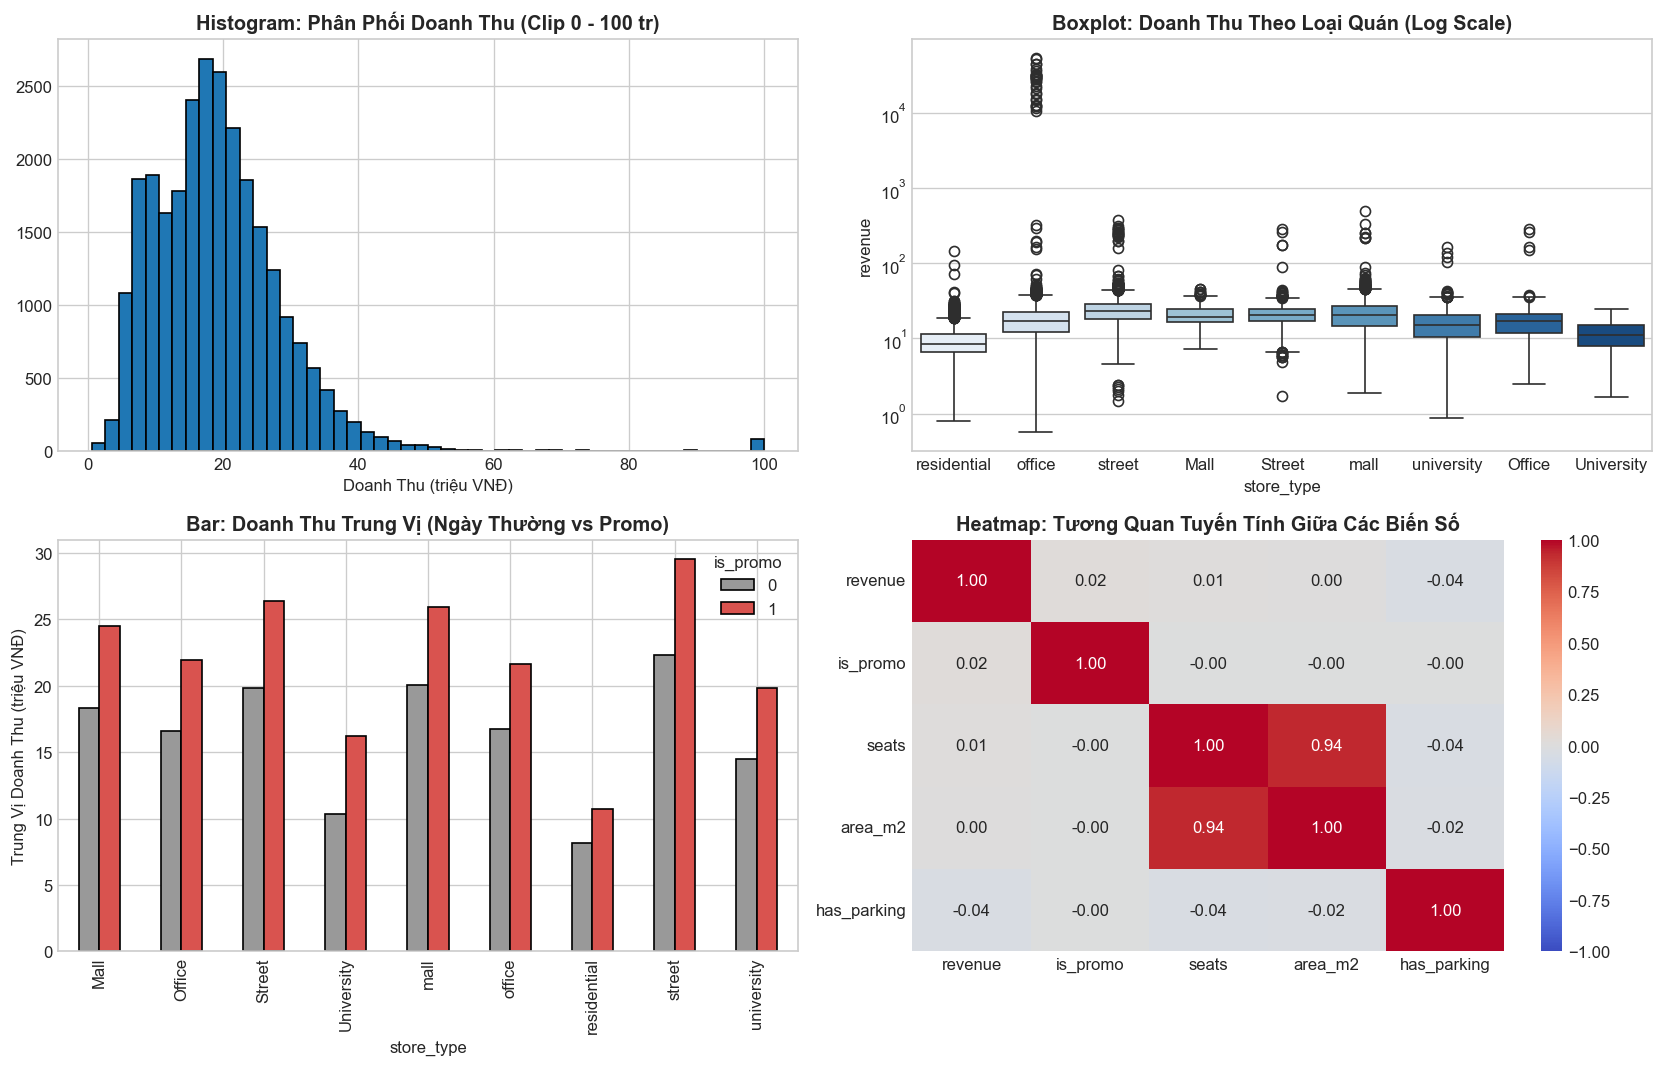

>>> HOÀN THÀNH STEP 2: ĐÃ XÁC ĐỊNH TOÀN BỘ CÁC VẤN ĐỀ VÀ MỐI QUAN HỆ ĐẶC TRƯNG!


In [3]:
# Ghép train với stores để trực quan hóa
train_merged = train.merge(stores, on="store_id", how="left")
train_merged["date"] = pd.to_datetime(train_merged["date"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Histogram Doanh thu (giới hạn 0 - 100 để thấy hình dáng thực tế)
axes[0, 0].hist(train_merged["revenue"].clip(0, 100), bins=50, color="#1f77b4", edgecolor="black")
axes[0, 0].set_title("Histogram: Phân Phối Doanh Thu (Clip 0 - 100 tr)", fontweight="bold")
axes[0, 0].set_xlabel("Doanh Thu (triệu VNĐ)")

# 2. Boxplot Doanh thu theo loại quán (Log-scale)
sns.boxplot(data=train_merged, x="store_type", y="revenue", ax=axes[0, 1], palette="Blues")
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Boxplot: Doanh Thu Theo Loại Quán (Log Scale)", fontweight="bold")

# 3. Bar plot: Tác động của khuyến mãi
promo_bar = train_merged.groupby(["store_type", "is_promo"])["revenue"].median().unstack()
promo_bar.plot(kind="bar", ax=axes[1, 0], color=["#999999", "#d9534f"], edgecolor="black")
axes[1, 0].set_title("Bar: Doanh Thu Trung Vị (Ngày Thường vs Promo)", fontweight="bold")
axes[1, 0].set_ylabel("Trung Vị Doanh Thu (triệu VNĐ)")

# 4. Correlation Heatmap
corr_num = train_merged[["revenue", "is_promo", "seats", "area_m2", "has_parking"]].corr()
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1], vmin=-1, vmax=1)
axes[1, 1].set_title("Heatmap: Tương Quan Tuyến Tính Giữa Các Biến Số", fontweight="bold")

plt.tight_layout()
plt.show()

print(">>> HOÀN THÀNH STEP 2: ĐÃ XÁC ĐỊNH TOÀN BỘ CÁC VẤN ĐỀ VÀ MỐI QUAN HỆ ĐẶC TRƯNG!")